# 05 — Feature engineering and enriched daily panel

This notebook expands the daily forecasting panel using only data already present in the project. Every approved feature is either:

- known by the end of trading day **t−1**, or
- known in advance for prediction date **t** (calendar fields).

Same-day trades, final daily volume, closing returns, auction price, and auction volume remain targets or diagnostics—not daily-model inputs. Intraday checkpoint features are deliberately left for a separate panel because they have a different information set.

In [1]:
from pathlib import Path
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 140)
pd.set_option("display.max_rows", 140)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 6), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")

DATA = PROJECT_ROOT / "blackrock_data"
OUT = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering"
OUT.mkdir(parents=True, exist_ok=True)
PANEL_PATH = OUT / "enriched_daily_panel.parquet"

AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

print(f"Project root: {PROJECT_ROOT}")
print(f"Output panel: {PANEL_PATH}")

Project root: /Users/aramesh/Documents/Fall 2026/Capstone
Output panel: /Users/aramesh/Documents/Fall 2026/Capstone/outputs/eda/05_feature_engineering/enriched_daily_panel.parquet


## Feature contract

The catalog below is the modeling contract. It identifies engineered features separately from identifiers, targets, and diagnostic outcomes. Ratios use `NULLIF` so that zero denominators become missing rather than infinite.

In [2]:
feature_groups = {
    "Auction history": [
        "lag1_auction_volume", "lag2_auction_volume", "lag5_auction_volume",
        "avg5_auction_volume", "avg20_auction_volume", "avg60_auction_volume",
        "median20_auction_volume", "median60_auction_volume",
        "std20_auction_volume", "std60_auction_volume", "auction_cv20",
        "auction_short_long_ratio", "lag1_auction_share", "avg20_auction_share",
        "std20_auction_share", "lag1_auction_to_adv20", "auction_spike_lag1",
        "days_since_last_auction", "prior_auction_observations",
    ],
    "Liquidity": [
        "lag1_daily_volume", "avg5_daily_volume", "avg20_daily_volume", "avg60_daily_volume",
        "std20_daily_volume", "std60_daily_volume", "abnormal_volume_lag1",
        "volume_short_long_ratio", "lag1_dollar_volume", "avg20_dollar_volume",
        "lag1_turnover", "avg20_turnover", "lag1_amihud", "avg20_amihud",
        "lag1_quoted_spread", "lag1_hl_range",
    ],
    "Returns and price": [
        "lag1_return", "lag1_abs_return", "momentum5", "momentum20", "momentum60",
        "volatility5", "volatility20", "volatility60", "max_abs_return20",
        "lag1_price", "lag1_overnight_gap",
    ],
    "Size and history": [
        "lag1_market_cap", "lag1_shares_outstanding", "prior_stock_observations",
        "data_age_days", "size_percentile", "liquidity_percentile",
        "turnover_percentile", "auction_intensity_percentile", "size_decile",
        "liquidity_decile",
    ],
    "Market state": [
        "lag1_market_return", "market_volatility20", "lag1_market_volume",
        "lag1_market_dollar_volume", "market_abnormal_volume_lag1",
        "lag1_market_dispersion", "lag1_market_breadth", "lag1_market_hl_range",
    ],
    "Sector state": [
        "lag1_sector_return", "sector_volatility20", "lag1_sector_volume",
        "lag1_sector_dollar_volume", "lag1_sector_dispersion", "lag1_sector_breadth",
        "stock_minus_sector_return", "stock_share_sector_volume",
    ],
    "Calendar": [
        "is_monday", "is_friday", "day_of_week", "month",
        "trading_day_of_month", "trading_days_to_month_end",
        "is_first_trading_day_month", "is_last_trading_day_month",
        "is_last_3_trading_days_month", "is_last_5_trading_days_month",
        "trading_days_to_quarter_end", "is_last_trading_day_quarter",
        "is_last_3_trading_days_quarter", "is_last_5_trading_days_quarter",
        "trading_days_to_year_end", "is_last_trading_day_year",
        "monthly_options_expiry", "quarterly_options_expiry",
        "after_long_market_gap", "before_long_market_gap", "is_early_close",
        "early_close_month_end_window", "expiry_month_end_window",
    ],
    "Security and corporate actions": [
        "ff12_code", "lag1_dividend_flag", "lag1_distribution_flag",
        "lag1_price_adjustment_flag",
    ],
}

catalog_rows = []
for group, features in feature_groups.items():
    for feature in features:
        timing = "Known in advance" if group == "Calendar" else "Through t-1"
        if feature == "ff12_code":
            timing = "Point-in-time classification"
        catalog_rows.append((feature, group, timing, "daily_safe", True))

catalog = pd.DataFrame(catalog_rows, columns=[
    "variable", "group", "information_time", "classification", "approved_daily_feature"
])
SAFE_FEATURES = catalog["variable"].tolist()
catalog.to_csv(OUT / "enriched_feature_catalog.csv", index=False)
catalog.to_csv(OUT / "approved_enriched_daily_features.csv", index=False)

print(f"Approved daily features: {len(SAFE_FEATURES)}")
display(catalog.groupby("group").size().rename("feature_count").to_frame())

Approved daily features: 99


,feature_count
group,
Auction history,19
Calendar,23
Liquidity,16
Market state,8
Returns and price,11
Sector state,8
Security and corporate actions,4
Size and history,10


## Construct the enriched panel

Rolling stock-level windows end at `1 PRECEDING`. Market and sector variables are explicitly lagged. Cross-sectional ranks are formed on prediction date *t* using only lagged stock information.

In [3]:
panel_sql = f"""
WITH crsp_row AS (
    SELECT date, permno, ticker, close, open, high, low, bid, ask,
           daily_volume, daily_price_volume, return_total, market_cap_usd,
           shares_outstanding_thousands, ordinary_dividend, nonordinary_dividend,
           daily_price_factor, distribution_flag,
           security_type, security_subtype, share_type, us_incorporated, issuer_type,
           daily_volume * 1.0 / nullif(shares_outstanding_thousands * 1000.0, 0) AS turnover,
           abs(return_total) * 1000000.0 / nullif(daily_price_volume, 0) AS amihud,
           CASE WHEN ask >= bid AND ask + bid > 0
                THEN (ask - bid) / ((ask + bid) / 2.0) END AS quoted_spread,
           (high - low) / nullif(close, 0) AS hl_range,
           open / nullif(lag(close) OVER (PARTITION BY permno ORDER BY date), 0) - 1 AS overnight_gap
    FROM read_parquet('{CRSP}', union_by_name=true, hive_partitioning=true)
), auction AS (
    SELECT date, permno, auction_volume, auction_price,
           auction_share_daily_volume, target_found
    FROM read_parquet('{AUCTION}', union_by_name=true, hive_partitioning=true)
), base AS (
    SELECT c.*, a.auction_volume, a.auction_price, a.auction_share_daily_volume,
           coalesce(a.target_found, false) AS target_found
    FROM crsp_row c LEFT JOIN auction a USING (date, permno)
), stock_history AS (
    SELECT *,
           lag(auction_volume, 1) OVER w AS lag1_auction_volume,
           lag(auction_volume, 2) OVER w AS lag2_auction_volume,
           lag(auction_volume, 5) OVER w AS lag5_auction_volume,
           avg(auction_volume) OVER w5 AS avg5_auction_volume,
           avg(auction_volume) OVER w20 AS avg20_auction_volume,
           avg(auction_volume) OVER w60 AS avg60_auction_volume,
           median(auction_volume) OVER w20 AS median20_auction_volume,
           median(auction_volume) OVER w60 AS median60_auction_volume,
           stddev_samp(auction_volume) OVER w20 AS std20_auction_volume,
           stddev_samp(auction_volume) OVER w60 AS std60_auction_volume,
           lag(auction_share_daily_volume, 1) OVER w AS lag1_auction_share,
           avg(auction_share_daily_volume) OVER w20 AS avg20_auction_share,
           stddev_samp(auction_share_daily_volume) OVER w20 AS std20_auction_share,
           date_diff('day', max(CASE WHEN auction_volume IS NOT NULL THEN date END) OVER wall, date)
             AS days_since_last_auction,
           count(auction_volume) OVER wall AS prior_auction_observations,
           count(*) OVER wall AS prior_stock_observations,
           date_diff('day', min(date) OVER (PARTITION BY permno), date) AS data_age_days,
           lag(daily_volume, 1) OVER w AS lag1_daily_volume,
           avg(daily_volume) OVER w5 AS avg5_daily_volume,
           avg(daily_volume) OVER w20 AS avg20_daily_volume,
           avg(daily_volume) OVER w60 AS avg60_daily_volume,
           stddev_samp(daily_volume) OVER w20 AS std20_daily_volume,
           stddev_samp(daily_volume) OVER w60 AS std60_daily_volume,
           lag(daily_price_volume, 1) OVER w AS lag1_dollar_volume,
           avg(daily_price_volume) OVER w20 AS avg20_dollar_volume,
           lag(turnover, 1) OVER w AS lag1_turnover,
           avg(turnover) OVER w20 AS avg20_turnover,
           lag(amihud, 1) OVER w AS lag1_amihud,
           avg(amihud) OVER w20 AS avg20_amihud,
           lag(quoted_spread, 1) OVER w AS lag1_quoted_spread,
           lag(hl_range, 1) OVER w AS lag1_hl_range,
           lag(return_total, 1) OVER w AS lag1_return,
           lag(abs(return_total), 1) OVER w AS lag1_abs_return,
           exp(sum(CASE WHEN return_total > -1 THEN ln(1 + return_total) END) OVER w5) - 1 AS momentum5,
           exp(sum(CASE WHEN return_total > -1 THEN ln(1 + return_total) END) OVER w20) - 1 AS momentum20,
           exp(sum(CASE WHEN return_total > -1 THEN ln(1 + return_total) END) OVER w60) - 1 AS momentum60,
           stddev_samp(return_total) OVER w5 AS volatility5,
           stddev_samp(return_total) OVER w20 AS volatility20,
           stddev_samp(return_total) OVER w60 AS volatility60,
           max(abs(return_total)) OVER w20 AS max_abs_return20,
           lag(close, 1) OVER w AS lag1_price,
           lag(overnight_gap, 1) OVER w AS lag1_overnight_gap,
           lag(market_cap_usd, 1) OVER w AS lag1_market_cap,
           lag(shares_outstanding_thousands * 1000.0, 1) OVER w AS lag1_shares_outstanding,
           lag((ordinary_dividend IS NOT NULL AND ordinary_dividend != 0)
               OR (nonordinary_dividend IS NOT NULL AND nonordinary_dividend != 0), 1) OVER w AS lag1_dividend_flag,
           lag(coalesce(distribution_flag, 'NO') != 'NO', 1) OVER w AS lag1_distribution_flag,
           lag(daily_price_factor IS NOT NULL AND abs(daily_price_factor - 1.0) > 1e-12, 1) OVER w
             AS lag1_price_adjustment_flag,
           lag(security_type, 1) OVER w AS lag1_security_type,
           lag(security_subtype, 1) OVER w AS lag1_security_subtype,
           lag(share_type, 1) OVER w AS lag1_share_type,
           lag(issuer_type, 1) OVER w AS lag1_issuer_type,
           lag(us_incorporated, 1) OVER w AS lag1_us_incorporated
    FROM base
    WINDOW
        w AS (PARTITION BY permno ORDER BY date),
        wall AS (PARTITION BY permno ORDER BY date ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),
        w5 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 5 PRECEDING AND 1 PRECEDING),
        w20 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING),
        w60 AS (PARTITION BY permno ORDER BY date ROWS BETWEEN 60 PRECEDING AND 1 PRECEDING)
), stock_features AS (
    SELECT *,
           std20_auction_volume / nullif(avg20_auction_volume, 0) AS auction_cv20,
           avg5_auction_volume / nullif(avg20_auction_volume, 0) AS auction_short_long_ratio,
           lag1_auction_volume / nullif(avg20_daily_volume, 0) AS lag1_auction_to_adv20,
           lag1_auction_volume > 2 * median20_auction_volume AS auction_spike_lag1,
           lag1_daily_volume / nullif(avg20_daily_volume, 0) AS abnormal_volume_lag1,
           avg5_daily_volume / nullif(avg20_daily_volume, 0) AS volume_short_long_ratio
    FROM stock_history
), market_history AS (
    SELECT date,
           lag(market_return_vw, 1) OVER w AS lag1_market_return,
           stddev_samp(market_return_vw) OVER w20 AS market_volatility20,
           lag(market_total_volume, 1) OVER w AS lag1_market_volume,
           lag(market_total_dollar_volume, 1) OVER w AS lag1_market_dollar_volume,
           lag(market_total_volume, 1) OVER w / nullif(avg(market_total_volume) OVER w20, 0)
             AS market_abnormal_volume_lag1,
           lag(market_return_dispersion, 1) OVER w AS lag1_market_dispersion,
           lag(market_breadth, 1) OVER w AS lag1_market_breadth,
           lag(market_median_hl_range, 1) OVER w AS lag1_market_hl_range
    FROM read_parquet('{MARKET}')
    WINDOW w AS (ORDER BY date), w20 AS (ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING)
), sector_history AS (
    SELECT date, ff12_code,
           lag(sector_return_vw, 1) OVER w AS lag1_sector_return,
           stddev_samp(sector_return_vw) OVER w20 AS sector_volatility20,
           lag(sector_total_volume, 1) OVER w AS lag1_sector_volume,
           lag(sector_total_dollar_volume, 1) OVER w AS lag1_sector_dollar_volume,
           lag(sector_return_dispersion, 1) OVER w AS lag1_sector_dispersion,
           lag(sector_breadth, 1) OVER w AS lag1_sector_breadth
    FROM read_parquet('{SECTOR}')
    WINDOW
        w AS (PARTITION BY ff12_code ORDER BY date),
        w20 AS (PARTITION BY ff12_code ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING)
), candidate AS (
    SELECT s.*, m.* EXCLUDE(date),
           e.* EXCLUDE(date, year, month, quarter, day),
           i.ff12_code, i.ff12_name, sh.* EXCLUDE(date, ff12_code),
           coalesce(an.exclude_from_model, false) AS exclude_source_anomaly,
           row_number() OVER (
               PARTITION BY s.date, s.permno
               ORDER BY i.secinfostartdt DESC NULLS LAST, i.secinfoenddt DESC NULLS LAST
           ) AS industry_rank
    FROM stock_features s
    LEFT JOIN market_history m USING (date)
    LEFT JOIN read_parquet('{EVENTS}') e USING (date)
    LEFT JOIN read_parquet('{INDUSTRY}') i
      ON s.permno = i.permno
     AND s.date BETWEEN i.secinfostartdt AND i.secinfoenddt
    LEFT JOIN sector_history sh
      ON s.date = sh.date AND i.ff12_code = sh.ff12_code
    LEFT JOIN read_parquet('{ANOMALIES}') an USING (date)
    WHERE s.date >= DATE '2015-01-01'
), deduplicated AS (
    SELECT * EXCLUDE(industry_rank) FROM candidate WHERE industry_rank = 1
), ranked AS (
    SELECT *,
           percent_rank() OVER (PARTITION BY date ORDER BY lag1_market_cap) AS size_percentile,
           percent_rank() OVER (PARTITION BY date ORDER BY avg20_daily_volume) AS liquidity_percentile,
           percent_rank() OVER (PARTITION BY date ORDER BY avg20_turnover) AS turnover_percentile,
           percent_rank() OVER (PARTITION BY date ORDER BY lag1_auction_to_adv20) AS auction_intensity_percentile,
           ntile(10) OVER (PARTITION BY date ORDER BY lag1_market_cap) AS size_decile,
           ntile(10) OVER (PARTITION BY date ORDER BY avg20_daily_volume) AS liquidity_decile
    FROM deduplicated
)
SELECT
    date, permno, ticker, year(date) AS year, month(date) AS month,
    CASE WHEN date <= DATE '2021-12-31' THEN 'train'
         WHEN date <= DATE '2023-12-31' THEN 'validation'
         ELSE 'test' END AS sample_split,
    target_found AS observed_target, exclude_source_anomaly,
    target_found AND auction_volume IS NOT NULL AND NOT exclude_source_anomaly AS eligible_target,
    auction_volume,
    CASE WHEN auction_volume IS NOT NULL THEN ln(1 + auction_volume) END AS log1p_auction_volume,
    auction_price, auction_share_daily_volume,
    daily_volume AS current_daily_volume, return_total AS current_return, close AS current_close,
    lag1_auction_volume, lag2_auction_volume, lag5_auction_volume,
    avg5_auction_volume, avg20_auction_volume, avg60_auction_volume,
    median20_auction_volume, median60_auction_volume,
    std20_auction_volume, std60_auction_volume, auction_cv20,
    auction_short_long_ratio, lag1_auction_share, avg20_auction_share,
    std20_auction_share, lag1_auction_to_adv20, auction_spike_lag1,
    days_since_last_auction, prior_auction_observations,
    lag1_daily_volume, avg5_daily_volume, avg20_daily_volume, avg60_daily_volume,
    std20_daily_volume, std60_daily_volume, abnormal_volume_lag1,
    volume_short_long_ratio, lag1_dollar_volume, avg20_dollar_volume,
    lag1_turnover, avg20_turnover, lag1_amihud, avg20_amihud,
    lag1_quoted_spread, lag1_hl_range,
    lag1_return, lag1_abs_return, momentum5, momentum20, momentum60,
    volatility5, volatility20, volatility60, max_abs_return20,
    lag1_price, lag1_overnight_gap,
    lag1_market_cap, lag1_shares_outstanding, prior_stock_observations,
    data_age_days, size_percentile, liquidity_percentile, turnover_percentile,
    auction_intensity_percentile, size_decile, liquidity_decile,
    lag1_market_return, market_volatility20, lag1_market_volume,
    lag1_market_dollar_volume, market_abnormal_volume_lag1,
    lag1_market_dispersion, lag1_market_breadth, lag1_market_hl_range,
    lag1_sector_return, sector_volatility20, lag1_sector_volume,
    lag1_sector_dollar_volume, lag1_sector_dispersion, lag1_sector_breadth,
    lag1_return - lag1_sector_return AS stock_minus_sector_return,
    lag1_daily_volume / nullif(lag1_sector_volume, 0) AS stock_share_sector_volume,
    is_monday, is_friday, day_of_week,
    trading_day_of_month, trading_days_to_month_end,
    is_first_trading_day_month, is_last_trading_day_month,
    is_last_3_trading_days_month, is_last_5_trading_days_month,
    trading_days_to_quarter_end, is_last_trading_day_quarter,
    is_last_3_trading_days_quarter, is_last_5_trading_days_quarter,
    trading_days_to_year_end, is_last_trading_day_year,
    monthly_options_expiry, quarterly_options_expiry,
    after_long_market_gap, before_long_market_gap, is_early_close,
    early_close_month_end_window, expiry_month_end_window,
    ff12_code, ff12_name, lag1_dividend_flag, lag1_distribution_flag,
    lag1_price_adjustment_flag, lag1_security_type, lag1_security_subtype,
    lag1_share_type, lag1_issuer_type, lag1_us_incorporated
FROM ranked
"""

escaped_path = str(PANEL_PATH).replace("'", "''")
con.execute(f"COPY ({panel_sql}) TO '{escaped_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
PANEL = str(PANEL_PATH)

overview = sql(f"""
SELECT count(*) AS rows, count(DISTINCT date) AS trading_days,
       count(DISTINCT permno) AS securities,
       count(*) FILTER (WHERE eligible_target) AS eligible_targets,
       min(date) AS first_date, max(date) AS last_date
FROM read_parquet('{PANEL}')
""")
display(overview)
print(f"Panel written: {PANEL_PATH.stat().st_size / 2**20:,.1f} MB")

,rows,trading_days,securities,eligible_targets,first_date,last_date
0,3594404,2766,2149,3499401,2015-01-02,2025-12-31


Panel written: 1,179.7 MB


## Integrity and leakage checks

The assertions verify uniqueness, target eligibility, cross-sectional percentile bounds, and that every cataloged model feature exists in the panel. They cannot replace substantive timing review, so the catalog remains the source of truth.

In [4]:
schema = sql(f"DESCRIBE SELECT * FROM read_parquet('{PANEL}')")
panel_columns = set(schema["column_name"])
missing_catalog_features = sorted(set(SAFE_FEATURES) - panel_columns)

integrity = sql(f"""
SELECT
    count(*) - count(DISTINCT (date, permno)) AS duplicate_keys,
    count(*) FILTER (WHERE eligible_target AND auction_volume IS NULL) AS eligible_without_target,
    count(*) FILTER (WHERE size_percentile NOT BETWEEN 0 AND 1) AS invalid_size_percentile,
    count(*) FILTER (WHERE liquidity_percentile NOT BETWEEN 0 AND 1) AS invalid_liquidity_percentile
FROM read_parquet('{PANEL}')
""")
display(integrity)
assert not missing_catalog_features, missing_catalog_features
assert integrity.loc[0, "duplicate_keys"] == 0
assert integrity.loc[0, "eligible_without_target"] == 0
assert integrity.loc[0, "invalid_size_percentile"] == 0
assert integrity.loc[0, "invalid_liquidity_percentile"] == 0

forbidden = {
    "auction_volume", "log1p_auction_volume", "auction_price",
    "auction_share_daily_volume", "current_daily_volume", "current_return", "current_close",
}
assert not forbidden.intersection(SAFE_FEATURES)
print("All integrity and daily-information-time checks passed.")

,duplicate_keys,eligible_without_target,invalid_size_percentile,invalid_liquidity_percentile
0,0,0,0,0


All integrity and daily-information-time checks passed.


## Missingness audit

,feature,eligible_rows,missing,missing_rate,distinct_values,group
2,lag5_auction_volume,3499401,28793,0.0082,668908,Auction history
1,lag2_auction_volume,3499401,21991,0.0063,669430,Auction history
12,lag1_auction_share,3499401,19682,0.0056,3474286,Auction history
16,auction_spike_lag1,3499401,19457,0.0056,2,Auction history
15,lag1_auction_to_adv20,3499401,19457,0.0056,3479716,Auction history
0,lag1_auction_volume,3499401,19457,0.0056,669741,Auction history
14,std20_auction_share,3499401,6264,0.0018,3492930,Auction history
8,std20_auction_volume,3499401,6167,0.0018,3491004,Auction history
10,auction_cv20,3499401,6167,0.0018,3491550,Auction history
11,auction_short_long_ratio,3499401,5696,0.0016,3480207,Auction history


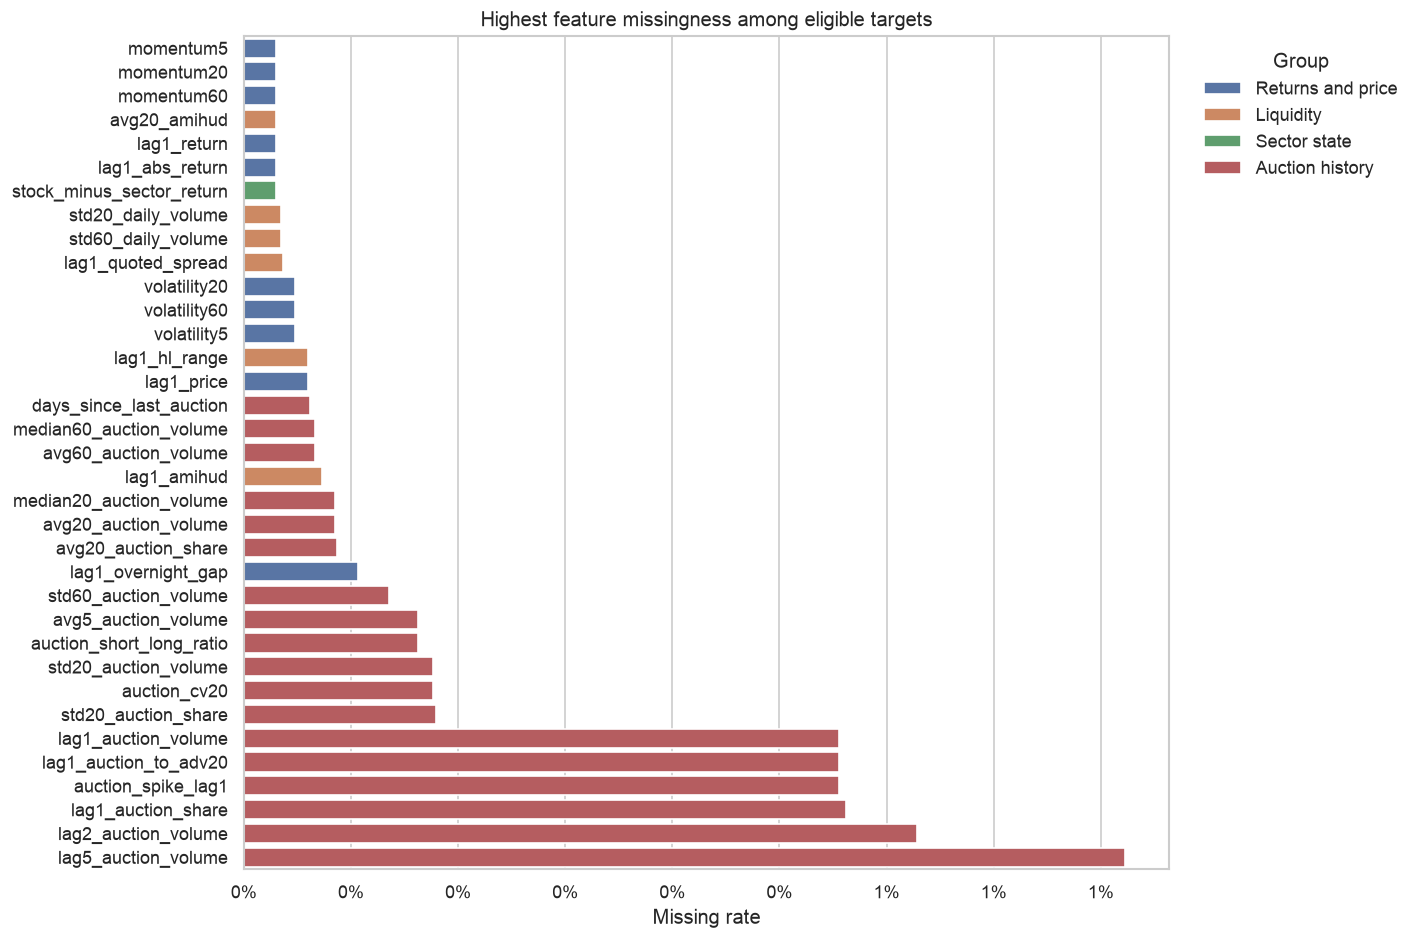

In [5]:
queries = []
for feature in SAFE_FEATURES:
    queries.append(f"""
        SELECT '{feature}' AS feature,
               count(*) FILTER (WHERE eligible_target) AS eligible_rows,
               count(*) FILTER (WHERE eligible_target AND \"{feature}\" IS NULL) AS missing,
               count(*) FILTER (WHERE eligible_target AND \"{feature}\" IS NULL)::DOUBLE
                   / nullif(count(*) FILTER (WHERE eligible_target), 0) AS missing_rate,
               count(DISTINCT \"{feature}\") FILTER (WHERE eligible_target) AS distinct_values
        FROM read_parquet('{PANEL}')
    """)

missingness = sql(" UNION ALL ".join(queries)).merge(
    catalog[["variable", "group"]], left_on="feature", right_on="variable", how="left"
).drop(columns="variable").sort_values("missing_rate", ascending=False)
missingness.to_csv(OUT / "enriched_feature_missingness.csv", index=False)
display(missingness.head(30))

fig, ax = plt.subplots(figsize=(12, 8))
plot_data = missingness.head(35).sort_values("missing_rate")
sns.barplot(data=plot_data, x="missing_rate", y="feature", hue="group", dodge=False, ax=ax)
ax.set(title="Highest feature missingness among eligible targets", xlabel="Missing rate", ylabel="")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
fig.tight_layout()
fig.savefig(OUT / "enriched_feature_missingness.png", bbox_inches="tight")
plt.show()

## Sanity checks on engineered ratios

Quantiles help expose impossible values or unstable denominators. Heavy tails are expected; later models should use `log1p`, signed-log, winsorization fitted on the training fold, or robust tree methods as appropriate.

In [6]:
ratio_features = [
    "auction_cv20", "auction_short_long_ratio", "lag1_auction_share",
    "lag1_auction_to_adv20", "abnormal_volume_lag1", "volume_short_long_ratio",
    "lag1_turnover", "lag1_amihud", "lag1_quoted_spread", "lag1_hl_range",
    "stock_share_sector_volume",
]
quantile_parts = []
for feature in ratio_features:
    quantile_parts.append(f"""
        SELECT '{feature}' AS feature,
               min({feature}) AS minimum,
               approx_quantile({feature}, 0.01) AS p01,
               approx_quantile({feature}, 0.50) AS median,
               approx_quantile({feature}, 0.99) AS p99,
               max({feature}) AS maximum
        FROM read_parquet('{PANEL}') WHERE eligible_target
    """)
ratio_quantiles = sql(" UNION ALL ".join(quantile_parts))
ratio_quantiles.to_csv(OUT / "engineered_ratio_quantiles.csv", index=False)
display(ratio_quantiles)

,feature,minimum,p01,median,p99,maximum
0,auction_cv20,0.0000,0.2402,0.6691,3.3210,4.4301
1,auction_short_long_ratio,0.0001,0.1897,0.9406,2.6822,12.3209
2,lag1_auction_share,0.0000,0.0038,0.0894,0.3953,1.0000
3,lag1_auction_to_adv20,0.0000,0.0029,0.0775,0.6825,15.1131
4,abnormal_volume_lag1,0.0000,0.2542,0.8871,3.4432,19.9723
5,volume_short_long_ratio,0.0000,0.4096,0.9563,2.1318,4.0000
6,lag1_turnover,0.0000,0.0004,0.0068,0.0714,27.2423
7,lag1_amihud,0.0000,0.0000,0.0004,0.2601,152.6268
8,lag1_quoted_spread,0.0000,0.0000,0.0005,0.0157,1.3693
9,lag1_hl_range,0.0000,0.0051,0.0259,0.1501,3.0588


## Compact redundancy screen

This is not a feature-selection step. It flags pairs that may be redundant in linear models. Tree models can still benefit from alternative horizons, while regularized linear models should avoid carrying many near-duplicates without shrinkage.

In [7]:
numeric_screen = [
    "lag1_auction_volume", "avg5_auction_volume", "avg20_auction_volume",
    "median20_auction_volume", "avg60_auction_volume", "lag1_auction_share",
    "lag1_daily_volume", "avg5_daily_volume", "avg20_daily_volume", "avg60_daily_volume",
    "lag1_turnover", "avg20_turnover", "momentum5", "momentum20", "momentum60",
    "volatility5", "volatility20", "volatility60", "lag1_market_cap",
]
log_features = {
    "lag1_auction_volume", "avg5_auction_volume", "avg20_auction_volume",
    "median20_auction_volume", "avg60_auction_volume", "lag1_daily_volume",
    "avg5_daily_volume", "avg20_daily_volume", "avg60_daily_volume", "lag1_market_cap",
}
select_expr = [
    f"ln(1 + {f}) AS {f}" if f in log_features else f
    for f in numeric_screen
]
sample = sql(f"""
SELECT {', '.join(select_expr)}
FROM read_parquet('{PANEL}')
WHERE eligible_target
USING SAMPLE 300000 ROWS (reservoir, 20261011)
""")
corr = sample.corr(numeric_only=True)
pairs = []
for i, left in enumerate(corr.columns):
    for right in corr.columns[i + 1:]:
        value = corr.loc[left, right]
        if pd.notna(value) and abs(value) >= 0.90:
            pairs.append({"feature_1": left, "feature_2": right, "correlation": value})
high_corr = pd.DataFrame(pairs).sort_values("correlation", key=lambda s: s.abs(), ascending=False)
high_corr.to_csv(OUT / "high_correlation_pairs.csv", index=False)
display(high_corr)

,feature_1,feature_2,correlation
16,avg20_daily_volume,avg60_daily_volume,0.9858
14,avg5_daily_volume,avg20_daily_volume,0.9786
7,avg20_auction_volume,median20_auction_volume,0.9764
8,avg20_auction_volume,avg60_auction_volume,0.9722
9,median20_auction_volume,avg60_auction_volume,0.9719
11,lag1_daily_volume,avg5_daily_volume,0.9677
15,avg5_daily_volume,avg60_daily_volume,0.9650
4,avg5_auction_volume,avg20_auction_volume,0.9626
5,avg5_auction_volume,median20_auction_volume,0.9587
12,lag1_daily_volume,avg20_daily_volume,0.9486


## Output summary

The enriched panel is now the canonical input for baseline and segmentation experiments. Model-specific transformations, imputation, winsorization, and segment cutoffs must be fitted inside each training window rather than globally.

In [8]:
summary = pd.DataFrame({
    "artifact": [
        "Enriched daily panel", "Approved feature catalog", "Missingness audit",
        "Ratio quantiles", "High-correlation pairs",
    ],
    "path": [
        str(PANEL_PATH), str(OUT / "approved_enriched_daily_features.csv"),
        str(OUT / "enriched_feature_missingness.csv"),
        str(OUT / "engineered_ratio_quantiles.csv"),
        str(OUT / "high_correlation_pairs.csv"),
    ],
})
display(summary)
summary.to_csv(OUT / "artifact_manifest.csv", index=False)

,artifact,path
0,Enriched daily panel,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,Approved feature catalog,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Missingness audit,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,Ratio quantiles,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
4,High-correlation pairs,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
